### Ciencia de Dados 2026.2 - Aula 8
#### Aluno : João Maria de Araujo Nogueira Junior | Matrícula : 20230041950

# Testes Paramétricos
Essa aula apresentou os testes paramétricos, que calculam o p-valor a partir de uma distribuição teórica em vez de simulações, e os requisitos que os sustentam como a normalidade, homocedasticidade e independência. 
Foram aplicados sete testes:
- t de uma amostra
- t de Welch
- t pareado
- ANOVA
- correlação de Pearson
- Z de duas proporções
- qui-quadrado

diferentes datasets utilizaram abordagens de analise e teste diferentes.

## 1. Primeiro Passo
Primeiramente, importei as bibliotecas e carreguei as cinco bases utilizadas na aula.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

sns.set_theme(style="whitegrid", palette="pastel")

In [4]:
mtcars = pd.read_csv("../data/mtcars/mtcars.csv")
penguins = pd.read_csv("../data/penguins/penguins.csv")
sleep = pd.read_csv("../data/sleep/sleep.csv")
iris = pd.read_csv("../data/iris/iris.csv")
titanic = pd.read_csv("../data/titanic/titanic.csv")

### 1.1 Bases utilizadas

- **mtcars**
- **penguins**
- **sleep**
- **iris**
- **titanic**

In [5]:
display(penguins.head()) #penguins
display(sleep.head())#sleep
display(iris.head())#iris
display(titanic.head())#titanic

,species,island,bill_len,bill_dep,flipper_len,body_mass,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


,extra,group,ID
0,0.7,1,1
1,-1.6,1,2
2,-0.2,1,3
3,-1.2,1,4
4,-0.1,1,5


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


No dataset do titanic, algumas colunas parecem repetir a mesma informação.

## 2. Utilidade do teste paramétrico

Testes paramétricos usam distribuições teóricas para calcular o p-valor. Sua confiabilidade depende de três premissas:

- **Normalidade:** os dados ou resíduos seguem uma distribuição normal. Ao e se falhar, o p-valor pode ficar incorreto em amostras pequenas.
- **Homocedasticidade:** os grupos possuem variâncias semelhantes. Se falhar, pode-se usar o teste de Welch.
- **Independência:** uma observação não influencia outra. Se falhar, é necessário ajustar o desenho do estudo.

A independência depende da coleta dos dados, a homocedasticidade pode ser verificada pelo teste de Levene e a normalidade será analisada a seguir.

### 2.1 Analise de sobreposição com a normal
Utilizei o Q-Q plot e teste de Shapiro-Wilk nas duas variáveis, milhas por galão (mpg do mtcars) e preço da passagem (fare do titanic).

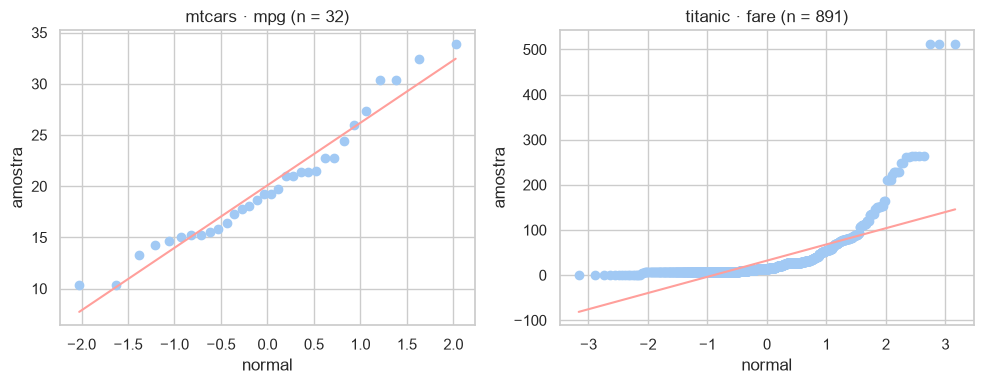

,W,p
mpg,0.947565,1.228814e-01
fare,0.521891,1.084045e-43


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, values, title in zip(
    axes,
    [mtcars["mpg"], titanic["fare"]],
    ["mtcars · mpg (n = 32)", "titanic · fare (n = 891)"],
):
    stats.probplot(values, dist="norm", plot=ax)
    ax.set(title=title, 
           xlabel="normal", 
           ylabel="amostra"
           )

plt.tight_layout()
plt.show()

pd.DataFrame(
    {
        "mpg": stats.shapiro(mtcars["mpg"]),
        "fare": stats.shapiro(titanic["fare"]),
    },
    index=["W", "p"],
).T

- **mpg:** os pontos seguem a reta, com W ≈ 0,95 e p ≈ 0,12, então não rejeito a normalidade.
- **fare:** no gráfico fica perceptivel que a distribuição forma uma curva forte e assimetria, com W ≈ 0,52 e p ≈ 0, então os dados não são proximos da normal.

O Shapiro funciona pior com datasets pequenos e rejeita desvios mínimos com n grande, por isso deve-se utilizar unidop ao Q-Q plot

## 3. Variaveis Relevantes

- **p-valor e α:** indicam se o resultado é significativo. Se p ≤ 0,05, rejeito H₀.
- **Tamanho do efeito:** mostra o quanto a diferença é relevante, usando medidas como diferença das médias.
- **Estatística de teste:** compara o efeito observado com a variação esperada pelo acaso. Pode seguir distribuições t, F ou normal.
- **Graus de liberdade:** representam a quantidade de informação disponível para o teste.
- **Intervalo de confiança:** indica uma faixa provável para o valor real do efeito.

## 4. Executando os testes

Cada dataset apresenta o contexto, as hipóteses, os requisitos, os cálculos, os gráficos e a interpretação dos resultados, vou analisar caso a caso e aplicar o melhor teste possivel.

### 4.1 Teste t de uma amostra
Primeiramente vou analisar o caso aonde a gestão de uma frota quer saber se o consumo médio dos veículos atende à meta de projeto de 20 mpg, com dados de 32 carros do mtcars.
- H₀: o consumo médio é igual à meta (μ = 20)
- H₁: o consumo médio é diferente da meta (μ ≠ 20)

Pra realizar esse teste precisa-se que as observações sejam independentes, e que sejam variável contínua e média aproximadamente normal, por isso foi feita analise anterior com Q-Q plot e o Shapiro Wilk.

Apliquei o teste t de uma amostra com o SciPy e calculei o intervalo de confiança:

In [7]:
# O mesmo teste com o SciPy
mpg = mtcars["mpg"]
target = 20
case1 = stats.ttest_1samp(mpg, popmean=target)
ci1 = case1.confidence_interval()

print(f"t = {case1.statistic:.3f}")
print(f"gl = {case1.df}")
print(f"p-valor = {case1.pvalue:.3f}")
print(f"IC 95% da média = [{ci1.low:.2f} ; {ci1.high:.2f}]")

t = 0.085
gl = 31
p-valor = 0.933
IC 95% da média = [17.92 ; 22.26]


A média da frota fica 0,09 mpg acima da meta esperada e menos de um décimo do erro-padrão. Sobre os requisitos, os carros são modelos distintos onde o consumo passou no Shapiro-Wilk.

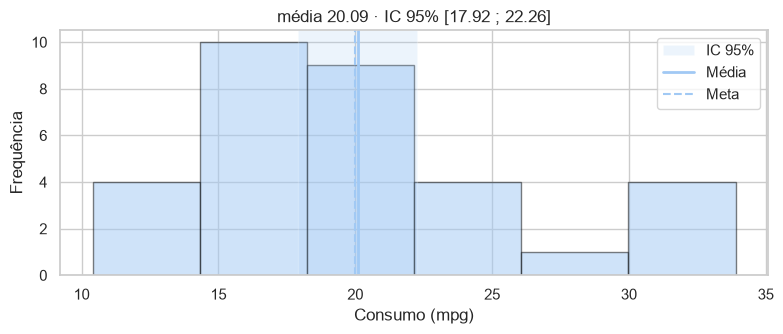

In [8]:
# Média e intervalo de confiança em relação a um valor de referência
def plot_hist_ci(values, ci, ref, xlabel, ax):
  mean = values.mean()

  ax.hist(values, bins="auto", alpha=0.5, edgecolor="black")
  ax.axvspan(ci.low, ci.high, alpha=0.2, label="IC 95%")
  ax.axvline(mean, linestyle="-", linewidth=2, label="Média")
  ax.axvline(ref, linestyle="--", linewidth=1.5, label="Meta")
  ax.set(
      xlabel=xlabel,
      ylabel="Frequência",
      title=f"média {mean:.2f} · IC 95% [{ci.low:.2f} ; {ci.high:.2f}]",
  )
  ax.legend()

fig, ax = plt.subplots(figsize=(8, 3.5))
plot_hist_ci(mpg, case1.confidence_interval(), target, "Consumo (mpg)", ax)
plt.tight_layout()
plt.show()

Os carros se distribuem dos dois lados da meta de 20 mpg, com IC de 17,9 a 22,3 mpg e p ≈ 0,93. Não se pode rejeitar $ H_0 $ mas isso não comprova que a média verdadeira seja 20 mpg.

### 4.2 Teste t de Welch

Em seguida, vou analisar se existe diferença entre a massa corporal média de pinguins machos e fêmeas, utilizando dados de 333 animais do dataset penguins.
- H₀: machos e fêmeas têm a mesma massa média (μ₁ = μ₂)
- H₁: as massas médias são diferentes (μ₁ ≠ μ₂)

Pra realizar esse teste, as observações precisam ser independentes dentro e entre os grupos, a variável deve ser contínua e apresentar normalidade aproximada em cada grupo. Diferentemente do teste t clássico, o Welch não exige variâncias iguais.

In [9]:
penguins_sex = penguins.dropna(subset=["sex", "body_mass"])

males = penguins_sex.loc[penguins_sex["sex"] == "male", "body_mass"]
females = penguins_sex.loc[penguins_sex["sex"] == "female", "body_mass"]

In [10]:
# Teste t de Welch com o SciPy
males = penguins_sex.loc[penguins_sex["sex"] == "male", "body_mass"]
females = penguins_sex.loc[penguins_sex["sex"] == "female", "body_mass"]
case2 = stats.ttest_ind(males, females, equal_var=False)

print(f"t de Welch (SciPy) = {case2.statistic:.3f}")
print(f"gl = {case2.df:.1f}")

t de Welch (SciPy) = 8.555
gl = 323.9


A diferença de 683 g cabe 8,55 vezes no erro-padrão (79,9 g), com gl ≈ 324 pela correção de Welch-Satterthwaite. Com mais de 160 animais por grupo, a média é aproximadamente normal. Falta checar as variâncias com o teste de Levene:

In [11]:
# Levene, IC da diferença e sobreposição dos grupos
ci = case2.confidence_interval()

print(f"Levene: p_valor = {stats.levene(males, females).pvalue:.3f}")
print(f"IC 95% da diferença: [{ci.low:.0f} ; {ci.high:.0f}] g")
print(f"fêmeas acima do macho médio: {(females > males.mean()).mean():.0%}")

Levene: p_valor = 0.014
IC 95% da diferença: [526 ; 841] g
fêmeas acima do macho médio: 25%


O desvio-padrão dos machos é maior que o das fêmeas e o Levene rejeita variâncias iguais (p ≈ 0,014), o que justifica o Welch. O IC 95% da diferença vai de 526 a 841 g, longe de zero. O gráfico mostra cada pinguim e a média de cada grupo, e a função `plot_group_means` será reutilizada na seção 4.4.

In [12]:
def plot_group_means(data, x, y, order, ylabel, ax):
  means = data.groupby(x)[y].mean().reindex(order)

  sns.boxplot(
      data=data,
      x=x,
      y=y,
      order=order,
      ax=ax,
      fill=False,
      whis=(0, 100),
      linewidth=1.2,
  )
  sns.stripplot(
      data=data, x=x, y=y, order=order, ax=ax, alpha=0.55, jitter=0.2, size=4
  )
  ax.scatter(
      np.arange(len(order)),
      means.values,
      marker="o",
      s=55,
      zorder=6,
      label="Média",
  )
  ax.set(xlabel="", ylabel=ylabel)

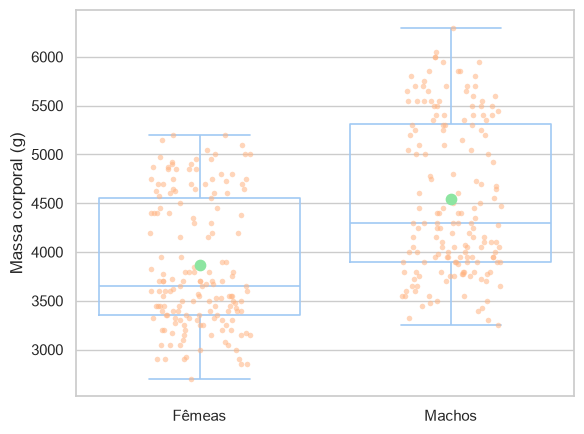

In [13]:
# massa corporal separada por sexo
fig, ax = plt.subplots(figsize=(6, 4.5))
plot_group_means(penguins_sex, "sex", "body_mass", ["female", "male"],
                 "Massa corporal (g)", ax)
ax.set_xticks([0, 1], ["Fêmeas", "Machos"])
plt.tight_layout()
plt.show()

##### Conclusão
os grupos se sobrepõem (25% das fêmeas pesam mais que o macho médio), mas a média dos machos fica bem acima. Se tivessem a mesma massa média, uma diferença de 683 g seria praticamente impossível por acaso (p < 0,001). Rejeito H₀: há evidência de dimorfismo sexual. O teste trata de médias e não afirma que todo macho pesa mais que toda fêmea.

#### Dimorfismo dentro de cada espécie
A base reúne 3 espécies de tamanhos bem diferentes, e comparar todos os machos com todas as fêmeas mistura a variação entre espécies com a variação entre sexos. Média e desvio-padrão por espécie e sexo:

In [14]:
penguins_sex.groupby(["species", "sex"]).body_mass.agg(["size", "mean", "std"]).round(0)

size    mean    std
species   sex                        
Adelie    female    73  3369.0  269.0
          male      73  4043.0  347.0
Chinstrap female    34  3527.0  285.0
          male      34  3939.0  362.0
Gentoo    female    58  4680.0  282.0
          male      61  5485.0  313.0

Em todas as espécies os machos pesam mais, e o desvio-padrão dentro de cada grupo (≈ 270 a 360 g) é bem menor que o do teste geral (> 660 g). A espécie pesa mais que o sexo: o macho Adelie típico (≈ 4.000 g) é mais leve que a fêmea Gentoo típica (≈ 4.700 g). Boxplot por espécie e Welch em cada uma:

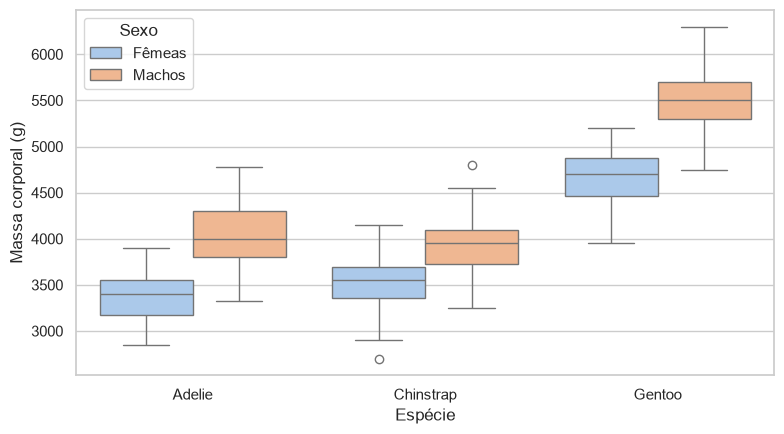

In [15]:
# Massa por espécie e sexo
fig, ax = plt.subplots(figsize=(8, 4.5))

sns.boxplot(
    data=penguins_sex,
    x="species",
    y="body_mass",
    order=["Adelie", "Chinstrap", "Gentoo"],
    hue="sex",
    hue_order=["female", "male"],
    ax=ax
)
ax.set(xlabel="Espécie", ylabel="Massa corporal (g)")

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Fêmeas", "Machos"], title="Sexo")

plt.tight_layout()
plt.show()

In [16]:
# Teste de Welch em cada espécie
for species, group in penguins_sex.groupby("species"):
    male = group.loc[group["sex"] == "male", "body_mass"]
    female = group.loc[group["sex"] == "female", "body_mass"]
    result = stats.ttest_ind(male, female, equal_var=False)
    ci_species = result.confidence_interval()
    print(f"{species}: t = {result.statistic:.3f} · gl = {result.df:.1f} · "
          f"p = {result.pvalue:.3g} · IC 95% [{ci_species.low:.0f} ; {ci_species.high:.0f}] g")

Adelie: t = 13.126 · gl = 135.7 · p = 6.4e-26 · IC 95% [573 ; 776] g
Chinstrap: t = 5.208 · gl = 62.6 · p = 2.26e-06 · IC 95% [254 ; 570] g
Gentoo: t = 14.761 · gl = 116.6 · p = 1.87e-28 · IC 95% [697 ; 913] g


O dimorfismo aparece nas 3 espécies (p < 0,001 em todas). Em Adelie e Gentoo o t (13,1 e 14,8) supera o do teste geral (8,55), mesmo com menos animais, porque o erro-padrão cai de ≈ 80 g para ≈ 50 g. A diferença também varia entre espécies: ≈ 800 g em Gentoo e ≈ 410 g em Chinstrap. Separar os grupos deixa a pergunta mais honesta e o teste mais preciso.

### 4.3 Teste t pareado

No casso do dataset sleep é necessario comparar o sono produzido pelas duas drogas nos mesmos 10 pacientes.

- H₀: μ_D = 0
- H₁: μ_D ≠ 0

para este cenario os requisitos são pares dependentes, diferenças aproximadamente normais e sem relação entre pacientes.

In [17]:
# Uma linha por paciente, com a diferença entre as drogas
sleep_wide = (
    sleep
    .pivot(index="ID", columns="group", values="extra")
    .rename(columns={1: "droga_1", 2: "droga_2"})
    .assign(D=lambda df: df["droga_2"] - df["droga_1"])
)

sleep_wide

group,droga_1,droga_2,D
ID,,,
1,0.7,1.9,1.2
2,-1.6,0.8,2.4
3,-0.2,1.1,1.3
4,-1.2,0.1,1.3
5,-0.1,-0.1,0.0
6,3.4,4.4,1.0
7,3.7,5.5,1.8
8,0.8,1.6,0.8
9,0.0,4.6,4.6


O pareado equivale a um teste t de uma amostra sobre as diferenças:

In [18]:
# Teste pareado e teste ignorando o pareamento
case3 = stats.ttest_rel(sleep_wide["droga_2"], sleep_wide["droga_1"])
unpaired = stats.ttest_ind(sleep_wide["droga_2"], sleep_wide["droga_1"])

pd.DataFrame({"t": [case3.statistic, unpaired.statistic], "p": [case3.pvalue, unpaired.pvalue]},index=["pareado", "ignorando o pareamento"]).round(4)

,t,p
pareado,4.0621,0.0028
ignorando o pareamento,1.8608,0.0792


O teste pareado produz t = 4,06 e p ≈ 0,003:

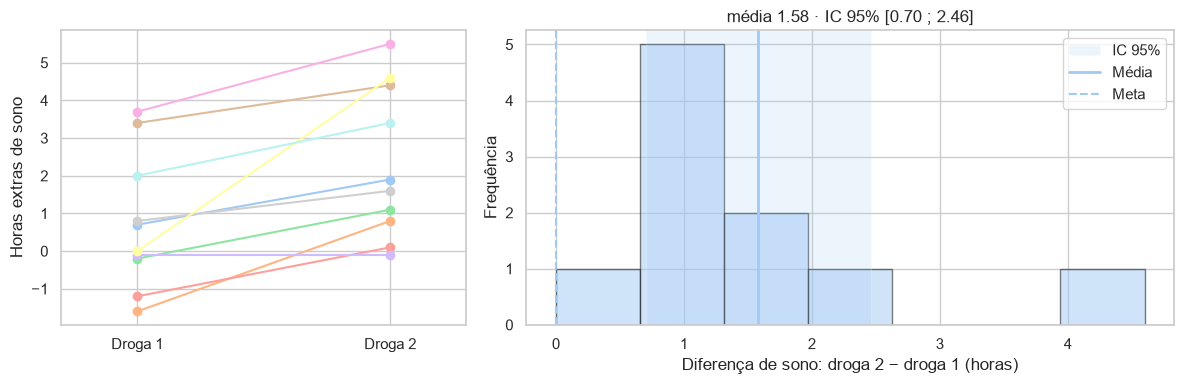

In [19]:
# Pacientes e diferenças com média e IC
fig, axes = plt.subplots(1, 2, figsize=(12, 4), width_ratios=[1, 1.6])

axes[0].plot([0, 1], sleep_wide[["droga_1", "droga_2"]].T, marker="o")
axes[0].set(xticks=[0, 1], xticklabels=["Droga 1", "Droga 2"], xlim=(-.3, 1.3),ylabel="Horas extras de sono")

plot_hist_ci(sleep_wide["D"], case3.confidence_interval(), 0,"Diferença de sono: droga 2 − droga 1 (horas)", axes[1])
plt.tight_layout()
plt.show()

Com apenas 10 diferenças, foram aplicados Shapiro-Wilk e Wilcoxon:

In [20]:
# Shapiro-Wilk das diferenças e Wilcoxon
shapiro_d = stats.shapiro(sleep_wide["D"])
wilcoxon_d = stats.wilcoxon(sleep_wide["D"])

print(f"Shapiro-Wilk das diferenças: W = {shapiro_d.statistic:.3f} · p = {shapiro_d.pvalue:.3f}")
print(f"Wilcoxon: T = {wilcoxon_d.statistic:.1f} · p = {wilcoxon_d.pvalue:.3f}")

Shapiro-Wilk das diferenças: W = 0.830 · p = 0.033
Wilcoxon: T = 0.0 · p = 0.004


O Shapiro-Wilk rejeita a normalidade das diferenças (p ≈ 0,03). O Wilcoxon chega à mesma conclusão (p ≈ 0,004). Rejeito H₀: a droga 2 aumenta o sono em cerca de 1,6 h.

### 4.4 ANOVA one-way

Para o dataset Iris busca-se comparar o comprimento médio da sépala entre setosa, versicolor e virginica.

- H₀: μ₁ = μ₂ = μ₃
- H₁: pelo menos uma média é diferente

Requisitos do teste são de que as observações independentes, resíduos aproximadamente normais e variâncias iguais.

Aplicação da ANOVA e verificação dos requisitos:

In [21]:
# ANOVA e Levene com o SciPy
setosa, versicolor, virginica = [
    group["sepal_length"] for _, group in iris.groupby("species")
]
k, N = 3, len(iris)
anova = stats.f_oneway(setosa, versicolor, virginica)
levene_sepal = stats.levene(setosa, versicolor, virginica)

print(f"ANOVA: F = {anova.statistic:.3f} · gl = ({k - 1}, {N - k}) · p = {anova.pvalue:.3g}")
print(f"Levene: estatística = {levene_sepal.statistic:.3f} · p = {levene_sepal.pvalue:.3g}")

ANOVA: F = 119.265 · gl = (2, 147) · p = 1.67e-31
Levene: estatística = 6.353 · p = 0.00226


A ANOVA indica diferença entre os grupos (F ≈ 119,3; p < 0,001). Os pares são comparados pelo teste de Tukey:

In [22]:
# Tukey: quais pares diferem
print(stats.tukey_hsd(setosa, versicolor, virginica))

Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)     -0.930     0.000    -1.174    -0.686
 (0 - 2)     -1.582     0.000    -1.826    -1.338
 (1 - 0)      0.930     0.000     0.686     1.174
 (1 - 2)     -0.652     0.000    -0.896    -0.408
 (2 - 0)      1.582     0.000     1.338     1.826
 (2 - 1)      0.652     0.000     0.408     0.896



Os três pares diferem entre si (p < 0,001).

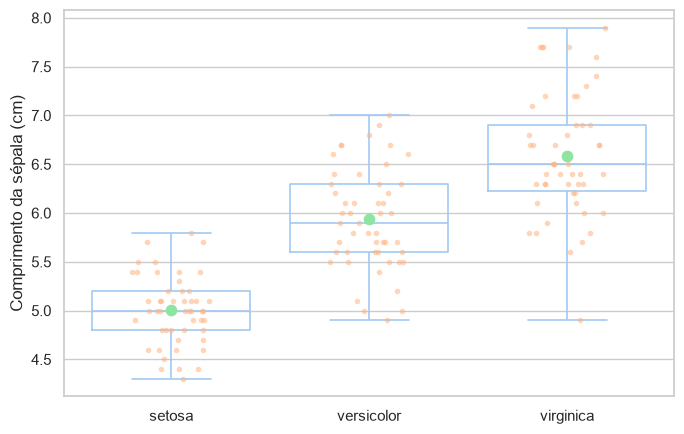

In [23]:
# Comprimento da sépala por espécie
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_group_means(iris, "species", "sepal_length", ["setosa", "versicolor", "virginica"],
                 "Comprimento da sépala (cm)", ax)
plt.tight_layout()
plt.show()

##### Conclusão
Dado os resultados deve-se rejeitar a H₀. As médias aumentam de setosa para versicolor e virginica (5.01 , 5.94 , 6.59 cm). O Levene detecta variâncias diferentes (p ≈ 0,002).

### 4.5 Correlação de Pearson

Novamente no dataset do mtcars busca-se verificar a relação linear entre peso e consumo dos veículos.

- H₀: ρ = 0
- H₁: ρ ≠ 0

Para realizar a analise dos Coeficiente de Pearson deve-se utilizar de pares independentes, variáveis contínuas e relação linear.

In [24]:
# Correlação de Pearson com o SciPy
case5 = stats.pearsonr(mtcars["wt"], mtcars["mpg"])
ci5 = case5.confidence_interval()

print(f"r (SciPy) = {case5.statistic:.3f} · p = {case5.pvalue:.3g} · IC 95% [{ci5.low:.2f} ; {ci5.high:.2f}]")

r (SciPy) = -0.868 · p = 1.29e-10 · IC 95% [-0.93 ; -0.74]


O r obtido pelo SciPy é −0,868 (p < 0,001), com IC 95% [−0,93; −0,74].

In [25]:
# Pearson com o peso em kg
r_kg = stats.pearsonr(mtcars["wt"] * 453.6, mtcars["mpg"]).statistic

print(f"r com o peso em kg = {r_kg:.3f}")

r com o peso em kg = -0.868


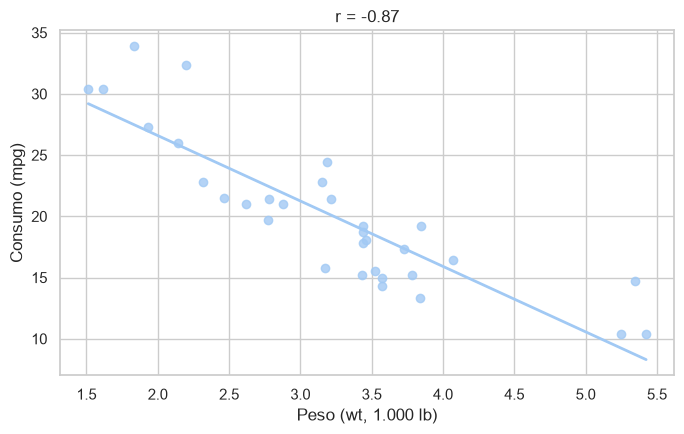

In [26]:
# Consumo x peso, com a reta de mínimos quadrados
slope, intercept = np.polyfit(mtcars["wt"], mtcars["mpg"], deg=1)
grid = np.linspace(mtcars["wt"].min(), mtcars["wt"].max(), 100)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(mtcars["wt"], mtcars["mpg"], alpha=.8)
ax.plot(grid, intercept + slope * grid, linewidth=2)
ax.set(title=f"r = {case5.statistic:.2f}", xlabel="Peso (wt, 1.000 lb)",
       ylabel="Consumo (mpg)")
plt.tight_layout()
plt.show()

**Conclusão:** rejeito H₀. Carros mais pesados tendem a apresentar menor consumo (menor mpg). Correlação não implica causalidade.

#### Transformação logarítmica

In [27]:
# Pearson com hp na escala original e em log
log_hp = np.log(mtcars["hp"])

r_hp = stats.pearsonr(mtcars["hp"], mtcars["mpg"])
r_log_hp = stats.pearsonr(log_hp, mtcars["mpg"])

print(f"Pearson com hp: r = {r_hp.statistic:.3f} · p = {r_hp.pvalue:.3g}")
print(f"Pearson com log(hp): r = {r_log_hp.statistic:.3f} · p = {r_log_hp.pvalue:.3g}")

Pearson com hp: r = -0.776 · p = 1.79e-07
Pearson com log(hp): r = -0.849 · p = 8.39e-10


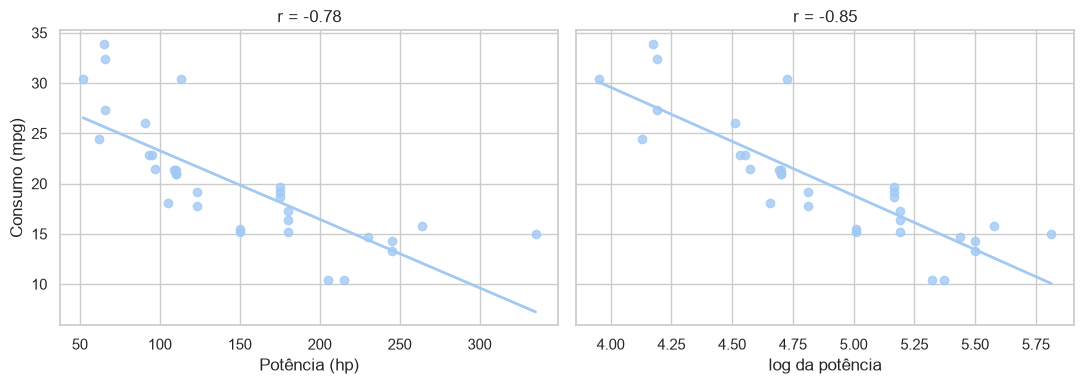

In [28]:
# Consumo x potência nas duas escalas
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

for ax, x, xlabel in zip(
    axes,
    [mtcars["hp"], log_hp],
    ["Potência (hp)", "log da potência"],
):
    slope, intercept = np.polyfit(x, mtcars["mpg"], deg=1)
    grid = np.linspace(x.min(), x.max(), 100)
    ax.scatter(x, mtcars["mpg"], alpha=.8)
    ax.plot(grid, intercept + slope * grid, linewidth=2)
    ax.set(xlabel=xlabel, title=f"r = {stats.pearsonr(x, mtcars['mpg']).statistic:.2f}")

axes[0].set_ylabel("Consumo (mpg)")
plt.tight_layout()
plt.show()

O r muda de −0,78 para −0,85 após a transformação log.

### 4.6 Teste Z de duas proporções

No dataset do Titanic para comparar a sobrevivência entre mulheres e homens do Titanic utiliza-se o teste Z de duas proporções.

- H₀: p_mulheres = p_homens
- H₁: p_mulheres ≠ p_homens

Os requisitos são respostas binárias, observações independentes e contagens esperadas suficientes.

In [29]:
# Sobreviventes, total e proporção por sexo
by_sex = (
    titanic
    .groupby("sex")
    .survived
    .agg(sobreviventes="sum", n="size")
    .assign(
        nao_sobreviventes=lambda df: df["n"] - df["sobreviventes"],
        proporcao=lambda df: df["sobreviventes"] / df["n"],
    )
)

by_sex.round(3)

,sobreviventes,n,nao_sobreviventes,proporcao
sex,,,,
female,233,314,81,0.742
male,109,577,468,0.189


Sobreviveram 74,2% das mulheres (233 de 314) e 18,9% dos homens (109 de 577); a menor contagem da condição é 81, muito acima de 5. Z de duas proporções pelo statsmodels:

In [30]:
# Z de duas proporções com statsmodels
p_pooled = by_sex["sobreviventes"].sum() / by_sex["n"].sum()
z_stat, z_p = proportions_ztest(by_sex["sobreviventes"], by_sex["n"])

print(f"proporção combinada = {p_pooled:.3f}")
print(f"Z (statsmodels) = {z_stat:.3f} · p = {z_p:.3g}")

proporção combinada = 0.384
Z (statsmodels) = 16.219 · p = 3.71e-59


A proporção combinada é 38,4%. Z ≈ 16,2 e p < 0,001:

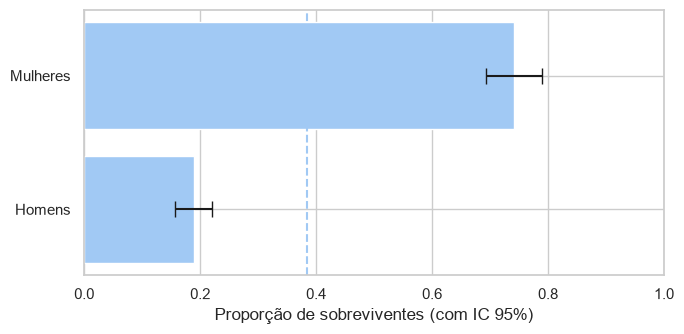

In [31]:
# Proporção de sobreviventes por sexo, com IC 95%
low, high = proportion_confint(by_sex["sobreviventes"], by_sex["n"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(["Homens", "Mulheres"], by_sex.loc[["male", "female"], "proporcao"],
        xerr=[(by_sex["proporcao"] - low)[["male", "female"]],
              (high - by_sex["proporcao"])[["male", "female"]]],
      capsize=6)
ax.axvline(p_pooled, linestyle="--")
ax.set(xlim=(0, 1), xlabel="Proporção de sobreviventes (com IC 95%)")
plt.tight_layout()
plt.show()

**Conclusão:** rejeito H₀. A taxa de sobrevivência foi cerca de 74,2% entre mulheres e 18,9% entre homens (p < 0,001).

### 4.7 Qui-quadrado de independência

Ainda no dataset do titanic pode-se verificar a associação entre classe da passagem e sobrevivência.

- H₀: classe e sobrevivência são independentes
- H₁: as variáveis estão associadas

O unico requisito é a contagens por célula e a frequências esperadas adequadas.

In [43]:
observed = (
    pd.crosstab(
        titanic["pclass"],
        titanic["survived"],
        rownames=["pclass"],
        colnames=["survived"],
        margins=True,
        margins_name="Total",
    )
    .rename(columns={0: "Não sobreviveu", 1: "Sobreviveu"})
)

observed

survived,Não sobreviveu,Sobreviveu,Total
pclass,,,
1,80,136,216
2,97,87,184
3,372,119,491
Total,549,342,891


O teste compara contagens observadas e esperadas:

In [44]:
case7 = stats.chi2_contingency(observed)

expected = pd.DataFrame(
    case7.expected_freq, index=observed.index, columns=observed.columns
)
contributions = (observed - expected) ** 2 / expected

print(f"χ² = {case7.statistic:.2f}, gl = {case7.dof}, p = {case7.pvalue:.1e}")

table = pd.concat({"esperado": expected,"(O−E)²/E": contributions},axis=1).swaplevel(0, 1, axis=1).sort_index(axis=1, level=0)

table.rename(columns={0: "Não sobreviveu", 1: "Sobreviveu"}, level=0).round(1)

χ² = 102.89, gl = 6, p = 6.3e-20


survived Não sobreviveu          Sobreviveu             Total         
               (O−E)²/E esperado   (O−E)²/E esperado (O−E)²/E esperado
pclass                                                                
1                  21.2    133.1       34.0     82.9      0.0    216.0
2                   2.4    113.4        3.8     70.6      0.0    184.0
3                  15.9    302.5       25.6    188.5      0.0    491.0
Total               0.0    549.0        0.0    342.0      0.0    891.0

O χ² é aproximadamente 102.9, com gl = 2 e p < 0,001.

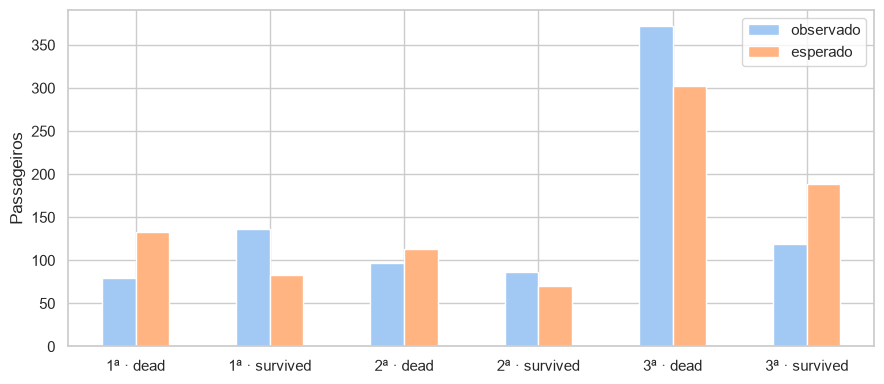

In [ ]:
#observadas x esperadas
comparison = (
  pd.concat(
    {"observado": observed.stack(), "esperado": expected.stack()},
    axis=1,
  )
  .rename(index={0: "dead", 1: "survived"}, level="survived")
)

fig, ax = plt.subplots(figsize=(9, 4))
comparison.plot.bar(ax=ax, rot=0)
ax.set_xticklabels([f"{c}ª · {d}" for c, d in comparison.index])
ax.set(xlabel="", ylabel="Passageiros")
plt.tight_layout()
plt.show()

**Conclusão:** rejeito H₀, pois a classe dos passageiros influencia significativamente suas chances de sobrevivência.

## Conclusões finais

Neste laboratório, entendi que o teste paramétrico troca a simulação por uma curva teórica em troca de premissas, e que o objetivo, a escala da variável e o desenho dos dados determinam o teste.